(electricity_gru)=
# Probabilistic forecasts of electricity load with a GRU

This example trains one GRU network on the hourly electricity load of 357 Portuguese clients and uses it for probabilistic day-ahead forecasts. The setup follows DeepAR {cite:p}`salinas2020deepar`. One network is shared by every client and trains on random windows of each client's history, scaled by the window's own level. It predicts a Student-t distribution for each hour, and it forecasts by feeding its own samples back in as inputs.

:::{include} /_includes/extra_installs.md
:::

In [1]:
import urllib.request
import zipfile

from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytensor
import pytensor.tensor as pt

from pytensor_distributions import studentt
from tqdm.auto import tqdm

from pytensor_ml.activations import SoftPlus
from pytensor_ml.layers import Embedding, GRUCell, Input, Linear
from pytensor_ml.model import Model
from pytensor_ml.optim import adamw, chain, clip_by_global_norm

## Data

The ElectricityLoadDiagrams20112014 dataset {cite:p}`trindade2015electricity` records the load of 370 clients every 15 minutes from 2011 to 2014, in kW. The readings are averaged to hourly load, and the example uses 2014. Clients with more than 10% zero hours that year are dropped, which leaves 357.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/321/electricityloaddiagrams20112014.zip"
data_path = Path("../data/electricity.zip")

if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, data_path)

with zipfile.ZipFile(data_path) as archive, archive.open("LD2011_2014.txt") as raw:
    readings = pd.read_csv(raw, sep=";", decimal=",", index_col=0, parse_dates=True)

hourly = readings.resample("1h", closed="right", label="right").mean().loc["2014-01-01 01:00":]
load = hourly.loc[:, (hourly == 0).mean() < 0.1]
load.shape

(8760, 357)

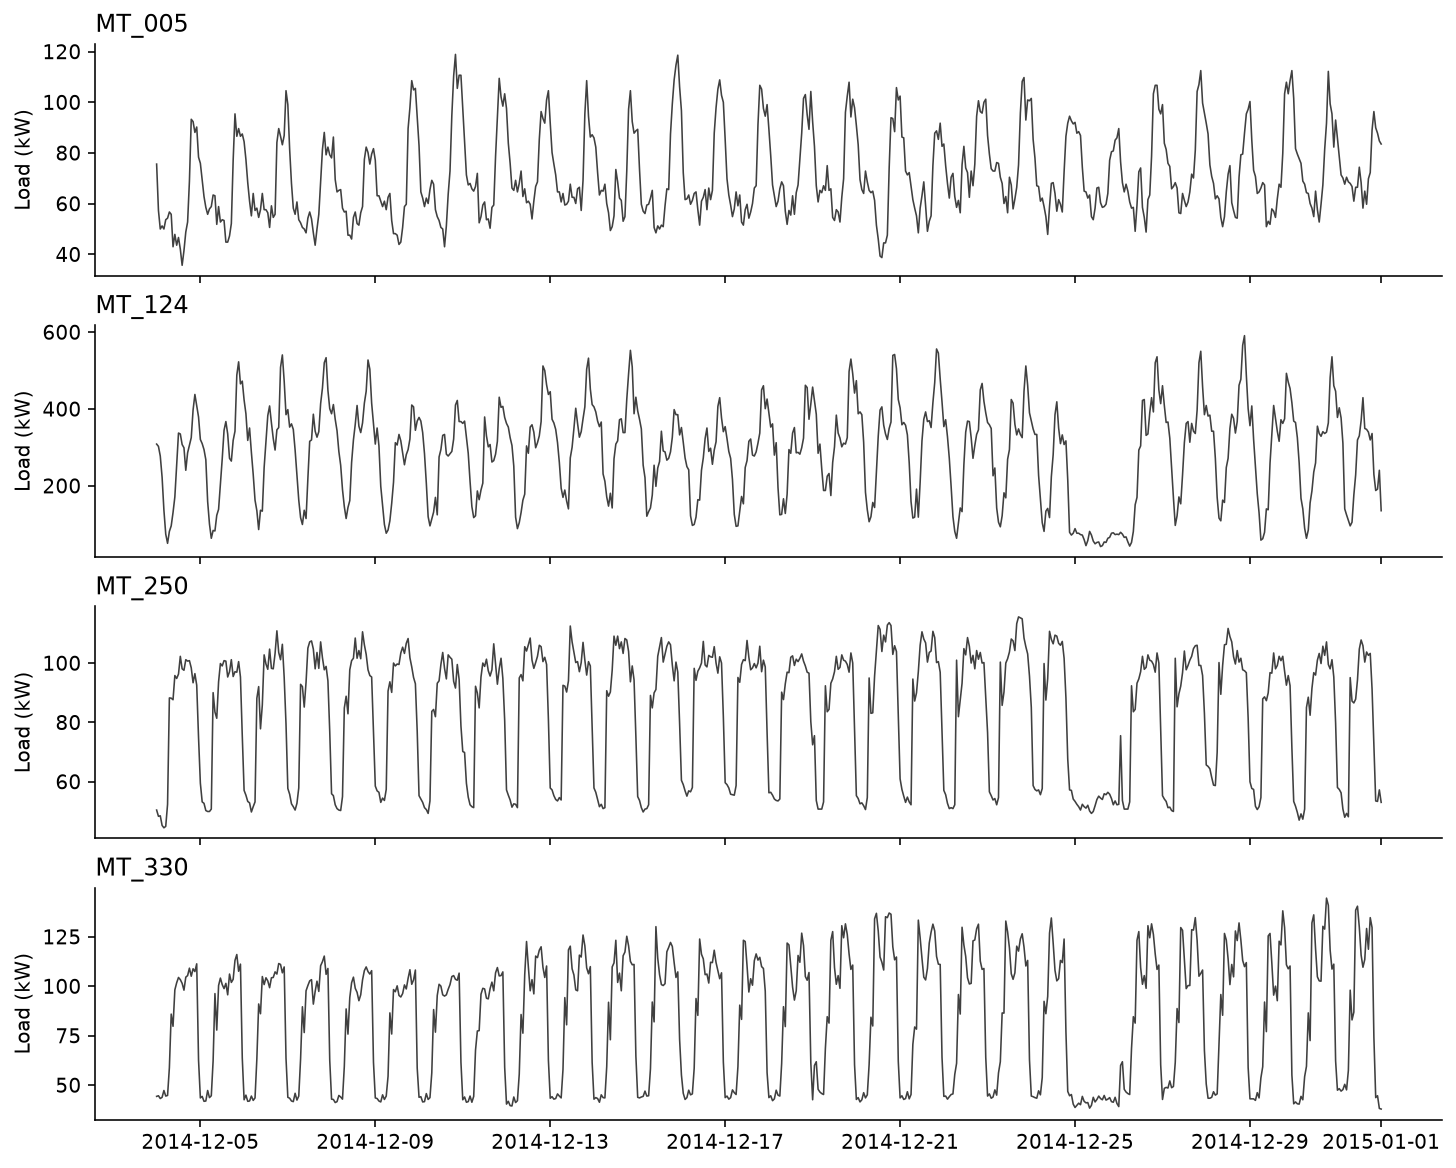

In [3]:
clients = ["MT_005", "MT_124", "MT_250", "MT_330"]
last_weeks = load.loc["2014-12-04":, clients]

fig, axes = plt.subplots(
    nrows=len(clients), figsize=(10, 8), dpi=144, sharex=True, layout="constrained"
)
for ax, client in zip(axes, clients):
    ax.plot(last_weeks.index, last_weeks[client], color="0.25", linewidth=0.8)
    ax.set_title(client, loc="left")
    ax.set_ylabel("Load (kW)")
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Training windows

A training example is one client's load over a 216-hour window: 24 hours that only serve as lagged inputs, a one-week context, and the 24 hours to forecast. Each window is divided by the client's mean load before the forecast day, so the network sees the shape of the load and not its level. A batch draws 64 windows at random clients and start times.

Each hour also carries calendar features, the hour of day and the day of week, as one-hot vectors. The last seven days of 2014, Christmas week, are held out for testing.

In [4]:
floatX = pytensor.config.floatX
hours_per_day = 24
horizon = hours_per_day
context_length = 7 * hours_per_day
window_length = hours_per_day + context_length + horizon
n_test_days = 7
# A client can switch off for days at a time, so a window's mean load can be zero.
scale_floor = 1.0

load_values = load.to_numpy(floatX)
n_hours, n_series = load_values.shape
n_train = n_hours - n_test_days * hours_per_day

hour_start = load.index - pd.Timedelta(hours=1)
calendar = np.concatenate(
    [np.eye(24, dtype=floatX)[hour_start.hour], np.eye(7, dtype=floatX)[hour_start.dayofweek]],
    axis=1,
)
n_calendar = calendar.shape[1]

In [5]:
def scaled_windows(starts, series):
    hours = starts[None, :] + np.arange(window_length)[:, None]
    windows = load_values[hours, series]
    window_scale = np.maximum(windows[:-horizon].mean(axis=0), scale_floor)
    return windows / window_scale, calendar[hours], window_scale


batch_size = 64
window_rng = np.random.default_rng(sum(map(ord, "electricity windows")))


def training_batch():
    starts = window_rng.integers(n_train - window_length + 1, size=batch_size)
    series = window_rng.integers(n_series, size=batch_size)
    windows, window_calendar, _ = scaled_windows(starts, series)
    return windows, window_calendar, series


forecast_origins = n_train + hours_per_day * np.arange(n_test_days)
test_series = np.tile(np.arange(n_series), n_test_days)
test_starts = np.repeat(forecast_origins - (window_length - horizon), n_series)
test_windows, test_calendar, test_scale = scaled_windows(test_starts, test_series)
test_windows.shape

(216, 2499)

## Model

Every hour, a GRU cell {cite:p}`cho2014gru` reads the previous hour's load, the load at the same hour the day before, the calendar features, and a learned embedding of the client. A linear head maps its hidden state to the degrees of freedom, location, and scale of a Student-t distribution over the next hour's scaled load. `advance` runs one step of the cell and `distribution` applies the head. Both work on any number of leading batch axes, so training and forecasting share them.

In [6]:
n_hidden = 64

series_ids = Input("series_ids", shape=(None,), dtype="int64")
client_embedding = Embedding("client", n_embeddings=n_series, n_features=16)
series_embedding = client_embedding(series_ids)

cell = GRUCell("gru", n_in=2 + n_calendar + client_embedding.n_features, n_hidden=n_hidden)
head = Linear("head", n_in=n_hidden, n_out=3)

In [7]:
def advance(yesterday, previous, calendar_now, hidden):
    batch_shape = tuple(previous.shape)
    features = pt.concatenate(
        [
            previous[..., None],
            yesterday[..., None],
            pt.broadcast_to(calendar_now, (*batch_shape, n_calendar)),
            pt.broadcast_to(series_embedding, (*batch_shape, client_embedding.n_features)),
        ],
        axis=-1,
    )
    (next_hidden,) = cell.step(features, hidden)
    return next_hidden


def distribution(hidden):
    outputs = head(hidden)
    nu = 2 + SoftPlus()(outputs[..., 0])
    loc = outputs[..., 1]
    scale = SoftPlus()(outputs[..., 2]) + 1e-3
    return nu, loc, scale

## Training

`pytensor.scan` runs `advance` over each window, with taps that hand every step the load one hour and 24 hours earlier. Every hour after the first day is a training target, and the loss is the negative Student-t log-density from pytensor-distributions. The held-out loss scores the forecast day of each test window one hour ahead, given the observed load up to that hour.

In [8]:
load_in = Input("load", shape=(None, None))
calendar_in = Input("calendar", shape=(None, None, n_calendar))

hidden_sequence = pytensor.scan(
    advance,
    sequences=[dict(input=load_in, taps=[-hours_per_day, -1]), calendar_in[hours_per_day:]],
    outputs_info=[pt.zeros((load_in.shape[1], n_hidden))],
    return_updates=False,
)
predicted = distribution(hidden_sequence)

targets = load_in[hours_per_day:]
train_nll = -studentt.logpdf(targets, *predicted).mean()
test_nll = -studentt.logpdf(
    targets[-horizon:], *(parameter[-horizon:] for parameter in predicted)
).mean()

In [9]:
network_inputs = [load_in, calendar_in, series_ids]

model = Model(predicted[1]).initialize(seed=0)
train_step = model.compile_train(
    chain(
        clip_by_global_norm(1.0),
        adamw(learning_rate=3e-3, weight_decay=0.01, mask=lambda parameter: parameter.ndim > 1),
    ),
    loss=train_nll,
    inputs=network_inputs,
)
evaluate_test = pytensor.function(network_inputs, test_nll)

In [10]:
n_steps = 2_000
eval_interval = 50
train_loss, test_loss = [], []

for step in tqdm(range(n_steps)):
    train_loss.append(train_step(*training_batch()))
    if step % eval_interval == 0:
        test_loss.append(evaluate_test(test_windows, test_calendar, test_series))

  0%|          | 0/2000 [00:00<?, ?it/s]

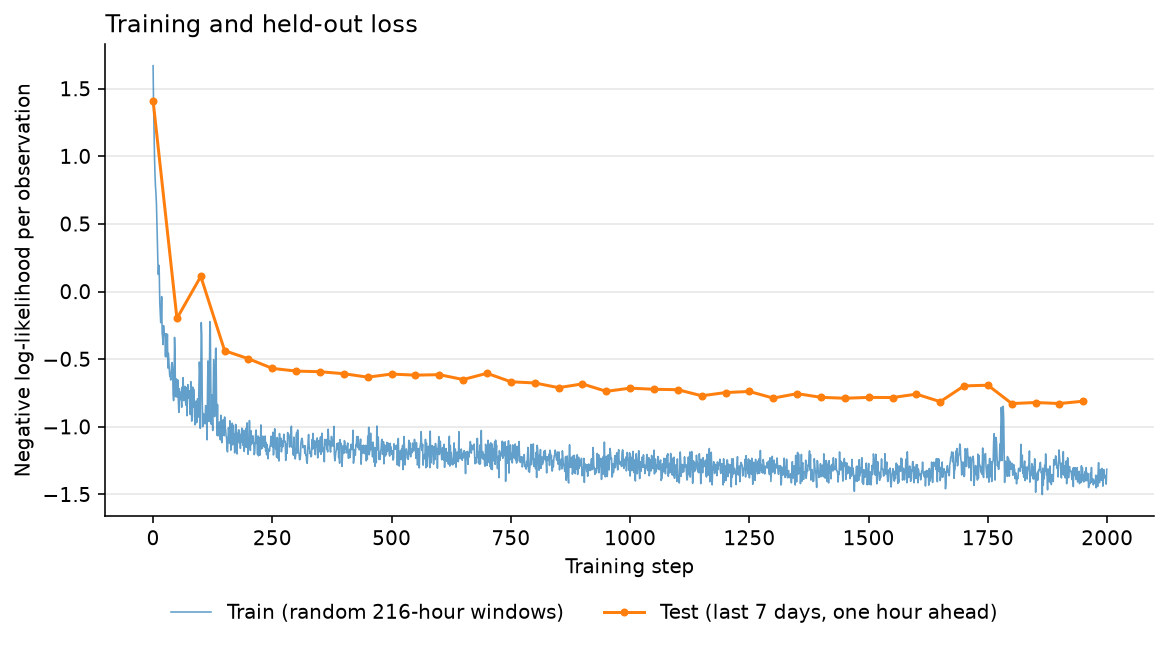

In [11]:
eval_steps = np.arange(0, n_steps, eval_interval)

fig, ax = plt.subplots(figsize=(8, 4), dpi=144, layout="constrained")
ax.plot(
    train_loss,
    color="C0",
    linewidth=0.8,
    alpha=0.7,
    label=f"Train (random {window_length}-hour windows)",
)
ax.plot(
    eval_steps,
    test_loss,
    color="C1",
    linewidth=1.5,
    marker="o",
    markersize=3,
    label=f"Test (last {n_test_days} days, one hour ahead)",
)

ax.set(xlabel="Training step", ylabel="Negative log-likelihood per observation")
ax.set_title("Training and held-out loss", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=len(labels),
    frameon=False,
)
plt.show()

## Forecasting

A forecast starts from the hidden state at the end of a window's context. Each step draws the next hour from the predicted Student-t with `pt.random.t` and feeds the draw back in as the next step's lagged load, so the 24 hours of a sample path are drawn jointly. The scan carries the random generator from one step to the next. Each of the seven test days gets 200 sample paths per client, starting from the observed load up to midnight.

In [12]:
def rollout_step(calendar_now, yesterday, previous, hidden, rng):
    next_hidden = advance(yesterday, previous, calendar_now, hidden)
    next_rng, sample = pt.random.t(*distribution(next_hidden), rng=rng, return_next_rng=True)
    return sample, next_hidden, next_rng


n_paths = 200
sample_rng = pytensor.shared(np.random.default_rng(sum(map(ord, "electricity forecasts"))))
calendar_ahead = Input("calendar_ahead", shape=(None, None, n_calendar))

n_windows = load_in.shape[1]
recent_load = pt.broadcast_to(load_in[-hours_per_day:, None], (hours_per_day, n_paths, n_windows))
initial_hidden = pt.broadcast_to(hidden_sequence[-1], (n_paths, n_windows, n_hidden))

sample_paths, _, final_rng = pytensor.scan(
    rollout_step,
    sequences=[calendar_ahead],
    outputs_info=[dict(initial=recent_load, taps=[-hours_per_day, -1]), initial_hidden, sample_rng],
    return_updates=False,
)
forecast_paths = pytensor.function(
    [*network_inputs, calendar_ahead], sample_paths, updates={sample_rng: final_rng}
)

In [13]:
scaled_paths = forecast_paths(
    test_windows[:-horizon], test_calendar[:-horizon], test_series, test_calendar[-horizon:]
)
forecast_quantiles = np.quantile(scaled_paths * test_scale, [0.05, 0.25, 0.5, 0.75, 0.95], axis=1)

actual = test_windows[-horizon:] * test_scale
seasonal_naive = test_windows[-2 * horizon : -horizon] * test_scale

## Results

The normalized deviation is the total absolute error of the median forecast divided by the total load, summed over all clients and hours, as in {cite:t}`salinas2020deepar`. The baseline repeats the previous day's load. The coverages count how often the observed load falls inside the 50% and 90% forecast intervals.

In [14]:
def normalized_deviation(prediction):
    return np.abs(prediction - actual).sum() / np.abs(actual).sum()


def coverage(lower, upper):
    return ((actual >= lower) & (actual <= upper)).mean()


lower_90, lower_50, median, upper_50, upper_90 = forecast_quantiles
pd.DataFrame(
    {
        "Normalized deviation": [
            normalized_deviation(median),
            normalized_deviation(seasonal_naive),
        ],
        "50% interval coverage": [coverage(lower_50, upper_50), np.nan],
        "90% interval coverage": [coverage(lower_90, upper_90), np.nan],
    },
    index=["GRU median", "Seasonal naive (yesterday)"],
).round(3)

,Normalized deviation,50% interval coverage,90% interval coverage
GRU median,0.184,0.359,0.686
Seasonal naive (yesterday),0.200,NaN,NaN


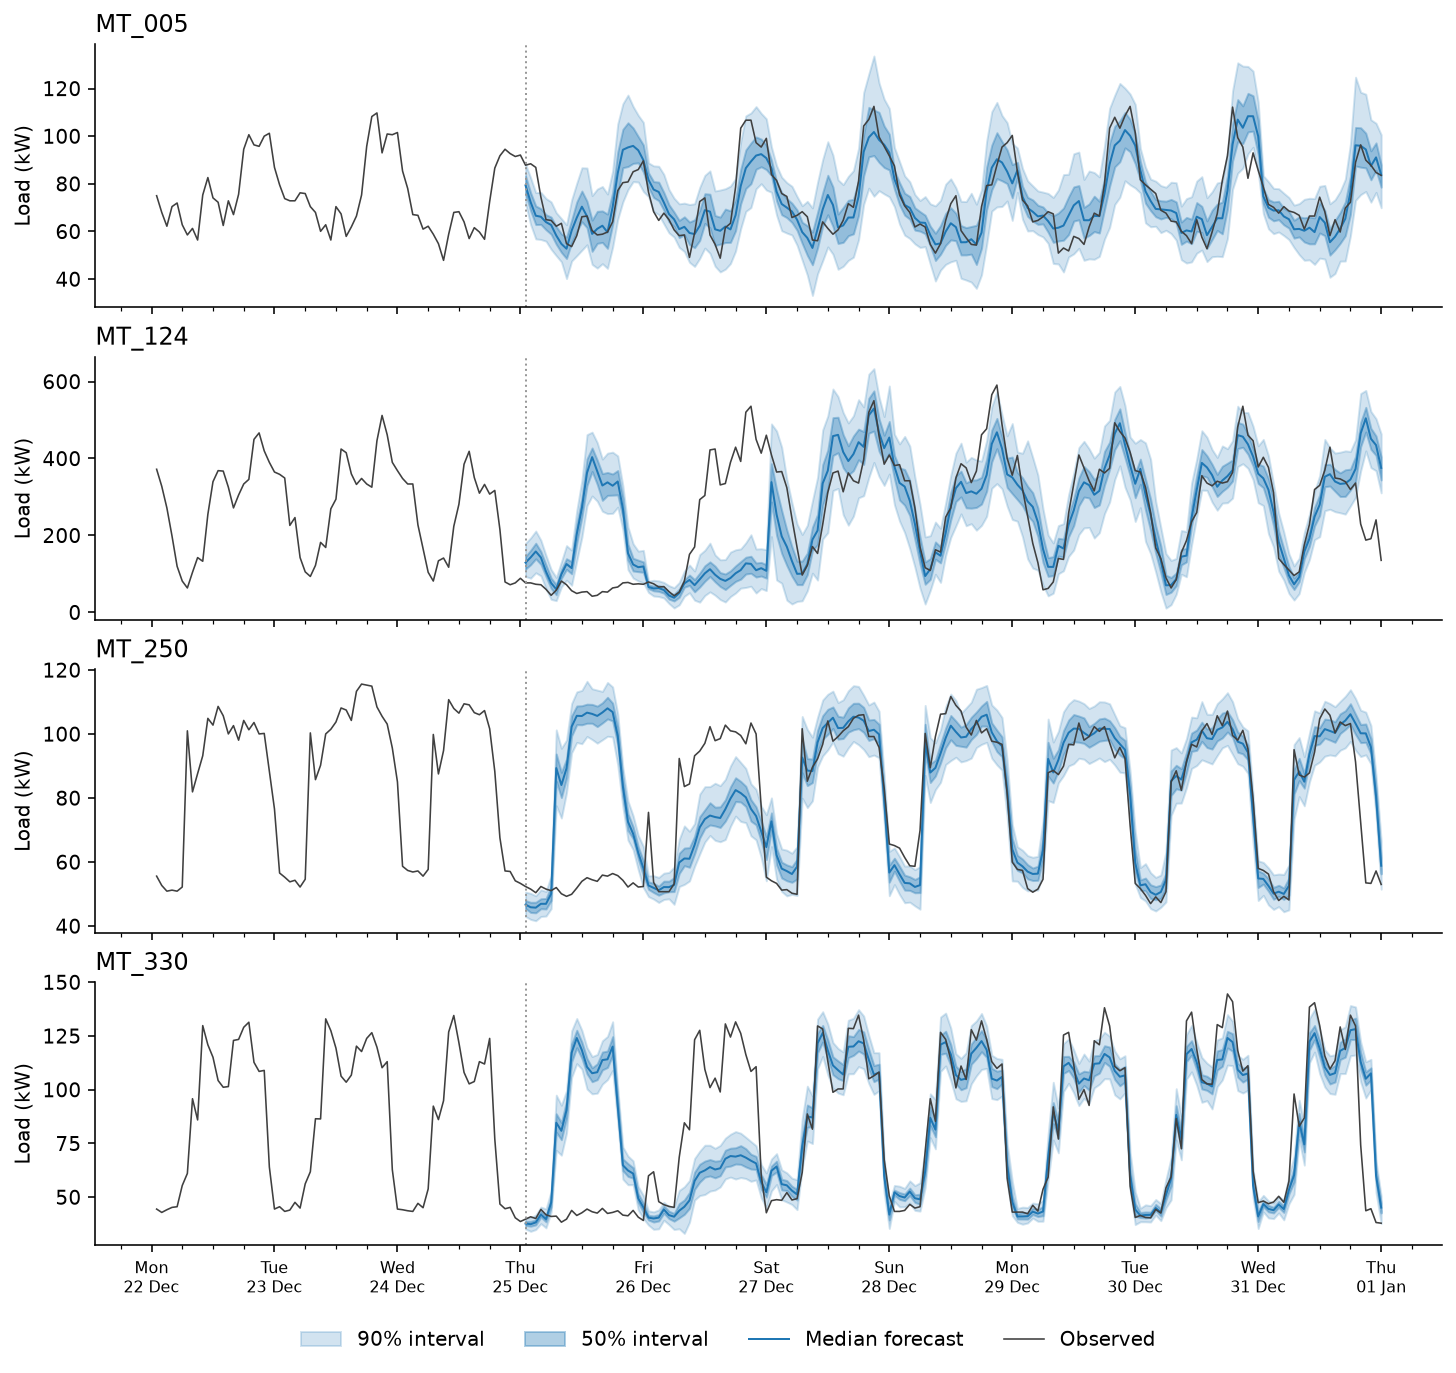

In [15]:
test_index = load.index[n_train:]
daily_quantiles = (
    forecast_quantiles.reshape(5, horizon, n_test_days, n_series)
    .transpose(0, 2, 1, 3)
    .reshape(5, n_test_days * horizon, n_series)
)

fig, axes = plt.subplots(
    nrows=len(clients), figsize=(10, 9), dpi=144, sharex=True, layout="constrained"
)
for ax, client in zip(axes, clients):
    lower_90, lower_50, median, upper_50, upper_90 = daily_quantiles[
        :, :, load.columns.get_loc(client)
    ]
    history = load[client].iloc[n_train - 3 * hours_per_day :]

    ax.fill_between(test_index, lower_90, upper_90, color="C0", alpha=0.2, label="90% interval")
    ax.fill_between(test_index, lower_50, upper_50, color="C0", alpha=0.35, label="50% interval")
    ax.plot(test_index, median, color="C0", linewidth=1.0, label="Median forecast")
    ax.plot(history.index, history, color="0.25", linewidth=0.8, label="Observed")
    ax.axvline(test_index[0], color="0.6", linestyle=":", linewidth=1)

    ax.set_title(client, loc="left")
    ax.set_ylabel("Load (kW)")
    ax.spines[["top", "right"]].set_visible(False)

axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a\n%d %b"))
axes[-1].xaxis.set_minor_locator(mdates.HourLocator(byhour=(6, 12, 18)))
axes[-1].tick_params(axis="x", which="major", labelsize=8)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=len(labels),
    frameon=False,
)
plt.show()

The forecasts follow each client's daily and weekly pattern. Christmas Day is the exception. Nothing in the inputs marks it as a holiday, so the network forecasts an ordinary Thursday, and its error that day is slightly larger than the baseline's.

## Limitations

On ordinary days the network does about as well as repeating the previous day. From the 27th to the 30th of December its normalized deviation is 0.075 to 0.093, against 0.066 to 0.100 for the baseline. The network sees the load 24 hours earlier but not a week earlier, and its held-out loss was still drifting down when training stopped at 2,000 steps. A weekly lag and a longer run are the first things to try.

The forecast intervals are too narrow. Over the whole week the 50% intervals contain 36% of the observed hours and the 90% intervals 69%. On the four ordinary days the figures are 44 to 51% and 81 to 89%, so most of the shortfall comes from the holidays, but the intervals are narrow even there. A likely cause is that the training loss scores each hour given the observed load before it, while a forecast feeds the network its own samples, so training never sees the errors that build up over the 24 forecast hours.

The calendar features cannot represent holidays, and a single year of data holds each one only once. On Christmas Day the normalized deviation is 0.72. On the 26th the network forecasts a low load because the day before was low, which helps for clients that stay closed and hurts for those that reopen.

The evaluation covers a single week, and two holidays dominate it. The numbers come from one training run with one seed, and a different test week would give different numbers. The model also uses no weather data, although electricity load depends on temperature.

## References

```{bibliography}
```

## Authors

- Created by Jesse Grabowski, November 8, 2026

## Watermark

In [16]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Sun, 08 Nov 2026

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.16.1

Compiler    : Clang 20.1.8 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

matplotlib            : 3.11.2
numpy                 : 2.5.4
pandas                : 3.0.5
pytensor              : 3.3.8
pytensor_distributions: 0.3.3
pytensor_ml           : 0.4.0
tqdm                  : 4.70.1

Watermark: 2.6.0

